# Exploratory data analysis
Online Retail II, cleaned by `src.data.clean` and validated by `src.data.validate`.

In [1]:
import sys, warnings, json
sys.path.insert(0, '..'); warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src.utils import load_config, load
from src.features.build import build_features, build_labels, data_end, feature_columns
cfg = load_config(); FIG = '../docs/figures/'
import os; os.makedirs(FIG, exist_ok=True)
sns.set_theme(style='whitegrid', palette=['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6'])
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
tx = pd.read_parquet(cfg['paths']['interim'])

In [2]:
print(tx.shape); tx.head()

(1027003, 14)


,invoice,stock_code,description,quantity,invoice_date,price,customer_id,country,is_admin,is_return,revenue,category,is_bulk,month
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,False,False,83.4,Christmas,False,2009-12
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,False,False,81.0,Lighting,False,2009-12
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,False,False,81.0,Lighting,False,2009-12
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,False,False,100.8,Home Decor,True,2009-12
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,False,False,30.0,Home Decor,False,2009-12


In [3]:
summary = {'rows': len(tx), 'customers': tx.customer_id.nunique(), 'guest_line_share': tx.customer_id.isna().mean(),
 'return_line_share': tx.is_return.mean(), 'first': tx.invoice_date.min(), 'last': tx.invoice_date.max()}
summary

{'rows': 1027003,
 'customers': 5939,
 'guest_line_share': np.float64(0.22317558955523986),
 'return_line_share': np.float64(0.018595856097791342),
 'first': Timestamp('2009-12-01 07:45:00'),
 'last': Timestamp('2011-12-09 12:50:00')}

## Univariate: spend, frequency, recency per customer

In [4]:
snap = pd.read_parquet(f"{cfg['paths']['processed']}/churn_snapshot.parquet")
snap[['recency_days','frequency','monetary_total','avg_order_value','return_rate']].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
recency_days,5256.0,206.93,174.40,1.00,50.00,164.00,325.00,648.00
frequency,5256.0,5.71,11.21,1.00,1.00,3.00,6.00,284.00
monetary_total,5256.0,2515.62,11791.90,0.00,310.05,758.34,2002.20,454202.09
avg_order_value,5256.0,364.85,532.71,1.55,173.85,275.02,406.99,14844.77
return_rate,5256.0,0.02,0.08,0.00,0.00,0.00,0.01,1.00


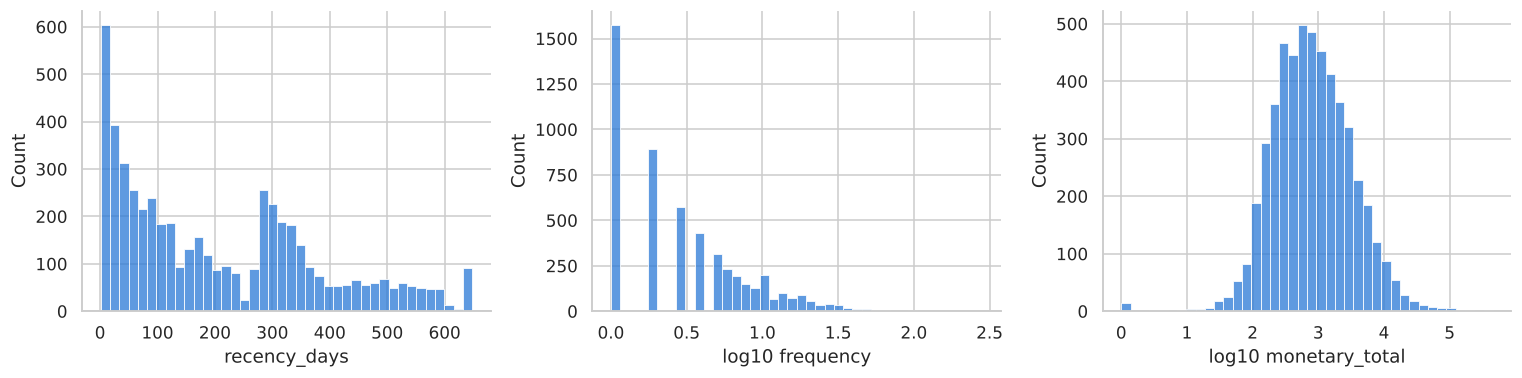

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
for a, col, log in zip(ax, ['recency_days', 'frequency', 'monetary_total'], [False, True, True]):
    sns.histplot(np.log10(snap[col].clip(lower=1)) if log else snap[col], ax=a, bins=40, color='#2a78d6')
    a.set_xlabel(('log10 ' if log else '') + col)
plt.tight_layout(); plt.savefig(FIG + 'eda_distributions.png')

## Bivariate: features vs churn and future value

active_months_last_year        -0.506
engagement_score               -0.491
frequency                      -0.432
monetary_total                 -0.414
revenue_last_90d               -0.412
orders_last_90d                -0.412
orders_same_season_last_year   -0.332
return_rate                    -0.196
avg_basket_items               -0.171
avg_order_value                -0.171
markdown_share                 -0.145
avg_basket_lines               -0.124
q4_share                       -0.090
product_popularity             -0.086
tenure_days                    -0.082
order_trend                     0.018
gap_std                         0.175
gap_mean                        0.195
overdue_ratio                   0.246
month_concentration             0.425
recency_days                    0.451
Name: churn, dtype: float64

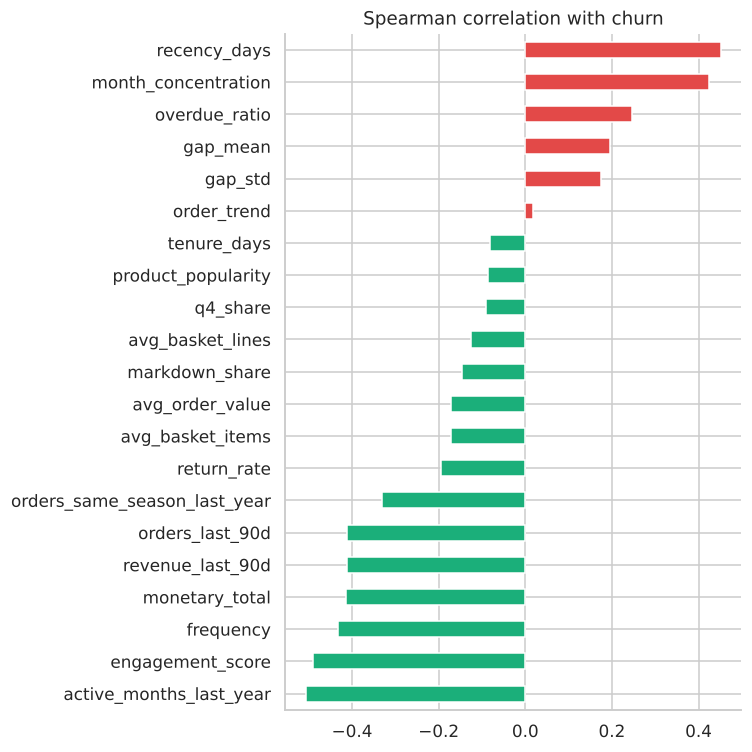

In [6]:
num = [c for c in feature_columns(snap.drop(columns=['churn','future_revenue'])) if not c.startswith(('cat_','country_'))]
corr = snap[num + ['churn']].corr(method='spearman')['churn'].drop('churn').sort_values()
ax = corr.plot.barh(figsize=(7, 7), color=np.where(corr > 0, '#e34948', '#1baf7a')); ax.set_title('Spearman correlation with churn')
plt.tight_layout(); plt.savefig(FIG + 'eda_churn_correlation.png'); corr.round(3)

In [7]:
clv = pd.read_parquet(f"{cfg['paths']['processed']}/clv_snapshot.parquet")
clv[num].corrwith(clv.future_revenue, method='spearman').sort_values(ascending=False).head(8).round(3)

engagement_score           0.623
monetary_total             0.618
frequency                  0.568
active_months_last_year    0.566
revenue_last_90d           0.558
orders_last_90d            0.504
avg_order_value            0.369
avg_basket_items           0.332
dtype: float64

## Multicollinearity (VIF)

In [8]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
X = np.log1p(snap[num].fillna(snap[num].median()).clip(lower=0)); X = (X - X.mean()) / X.std()
vif = pd.Series([variance_inflation_factor(X.values, i) for i in range(X.shape[1])], index=num).sort_values(ascending=False)
vif.round(1)

monetary_total                  66.8
frequency                       40.5
avg_order_value                 21.8
engagement_score                19.2
orders_last_90d                 16.2
revenue_last_90d                11.1
active_months_last_year         10.9
overdue_ratio                   10.1
month_concentration             10.1
gap_mean                         9.1
recency_days                     8.9
orders_same_season_last_year     5.6
tenure_days                      3.9
avg_basket_items                 3.6
order_trend                      2.8
return_rate                      2.6
avg_basket_lines                 2.6
markdown_share                   2.0
q4_share                         1.8
gap_std                          1.5
product_popularity               1.1
dtype: float64

High-VIF pairs (e.g. frequency vs. active months, revenue_last_90d vs. orders_last_90d) are kept: the production model is a tree ensemble, which is insensitive to collinearity, and the linear baseline is L1/L2 regularised.

## Country and seasonality

In [9]:
rev = tx[~tx.is_admin & tx.customer_id.notna()]
rev.groupby('country').revenue.sum().sort_values(ascending=False).head(10).div(1e3).round(0).rename('revenue £k')

country
United Kingdom    13645.0
EIRE                568.0
Netherlands         546.0
Germany             375.0
France              292.0
Australia           166.0
Switzerland          92.0
Spain                85.0
Sweden               84.0
Denmark              63.0
Name: revenue £k, dtype: float64

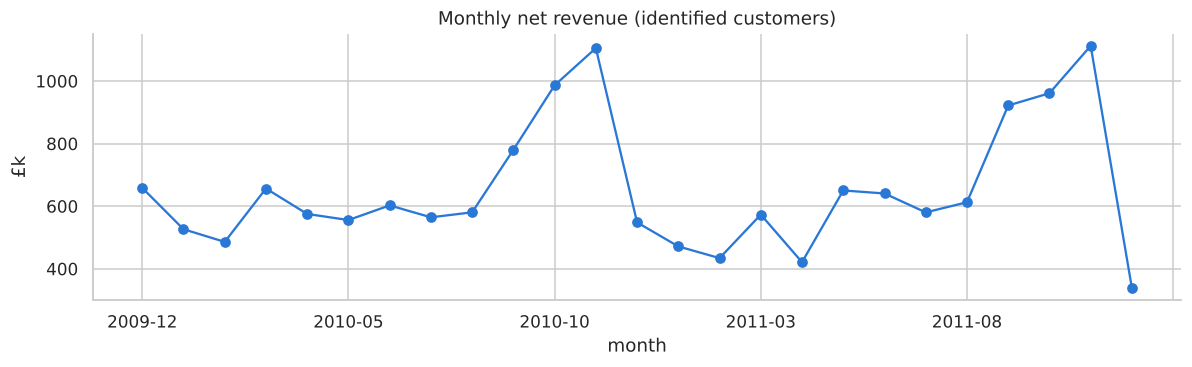

In [10]:
monthly = rev.groupby('month').revenue.sum()
ax = monthly.div(1e3).plot(figsize=(11, 3.5), marker='o', color='#2a78d6')
ax.set_ylabel('£k'); ax.set_title('Monthly net revenue (identified customers)'); plt.tight_layout(); plt.savefig(FIG + 'eda_monthly_revenue.png')

## Hypotheses for modelling
1. Recency is the strongest single churn signal, but its effect depends on each customer's usual order gap (overdue ratio).
2. Customers who bought in the same season last year are less likely to churn before Christmas.
3. Return rate and markdown share add signal beyond RFM.
4. Past spend is close to linear in future 12-month value; tree models will need help extrapolating whales (Tweedie loss or a linear model).
5. Spending behaviour forms a handful of interpretable segments (wholesalers, seasonal gift buyers, lapsed big spenders).